In [13]:
#Descripción: Registro histórico de clientes de un servicio de telecomunicaciones que integra variables
#sociodemográficas, características de contratación, desglose de facturación y estado de cancelación de
#la suscripción (Churn).

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import numpy as np
from matplotlib.patches import Patch

os.environ['KAGGLE_USERNAME'] = 'santiagobass'
os.environ['KAGGLE_KEY'] = 'KGAT_5ecec35b0e2137a251d209e054f331fd'

from kaggle.api.kaggle_api_extended import KaggleApi
api = KaggleApi()
api.authenticate()

download_path = './telco-customer-churn'

api.dataset_download_files('blastchar/telco-customer-churn', path=download_path, unzip=True)

csv_path = os.path.join(download_path, "WA_Fn-UseC_-Telco-Customer-Churn.csv")
df = pd.read_csv(csv_path)

#Limpieza de datos
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})
df['Churn_Num'] = df['Churn'].copy()

df.head()

Dataset URL: https://www.kaggle.com/datasets/blastchar/telco-customer-churn


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_Num
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,0
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.5,0,0
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,1
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,0
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,1


In [11]:
############## Limpieza de datos y calidad de datos ##############

# Las dimensiones del dataset
print("Cantidad de filas y columnas:", df.shape)

# Informacion general del dataset
df.info()

# Valores que faltan por columna
print("\nValores faltantes:")
print(df.isnull().sum())

# Estadisticas descriptivas
display(df.describe())

# Estadisticas de variables categoricas
display(df.describe(include="object"))

Cantidad de filas y columnas: (7043, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   object 
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  P

,tenure,MonthlyCharges,Churn,Churn_Num
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,0.265370,0.265370
std,24.559481,30.090047,0.441561,0.441561
min,0.000000,18.250000,0.000000,0.000000
25%,9.000000,35.500000,0.000000,0.000000
50%,29.000000,70.350000,0.000000,0.000000
75%,55.000000,89.850000,1.000000,1.000000
max,72.000000,118.750000,1.000000,1.000000


,customerID,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531
top,7590-VHVEG,Male,No,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,
freq,1,3555,5901,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11


In [ ]:
######## Deteccion de columnas vacias ########

# Reemplazo las cadenas vacias o con espacios NaN

df.replace(r'^\s*$', pd.NA, regex=True, inplace=True)

# Muestro la cantidad de faltantes por columna
faltantes = df.isnull().sum()

print("Valores faltantes por columna:")
print(faltantes[faltantes > 0])

print("Valores faltantes por TotalCharges:",
      df["TotalCharges"].isnull().sum())

display(df[df["TotalCharges"].isnull()])

######## Correccion de tipo de datos ########

# Convierto TotalCharges a tipo numerico

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Compruebo los tipos de datos
print(df.dtypes)

In [ ]:
############## Limpieza de datos y calidad de datos ##############

# Las dimensiones del dataset
print("Cantidad de filas y columnas:", df.shape)

# Informacion general del dataset
df.info()

# Valores que faltan por columna
print("\nValores faltantes:")
print(df.isnull().sum())

# Estadisticas descriptivas
display(df.describe())

# Estadisticas de variables categoricas
display(df.describe(include="object"))

Cantidad de filas y columnas: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  P

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [ ]:
################ Adecuación de Tipos de Datos ################

# Verifico que no queden valores nulos tras la conversión e imputación
print("Total de valores nulos en el dataset:", df.isnull().sum().sum())
print("\nTipos de datos confirmados:")
print(df[["tenure", "MonthlyCharges", "TotalCharges"]].dtypes)

Total de valores nulos en el dataset: 0

Tipos de datos confirmados:
tenure              int64
MonthlyCharges    float64
TotalCharges      float64
dtype: object


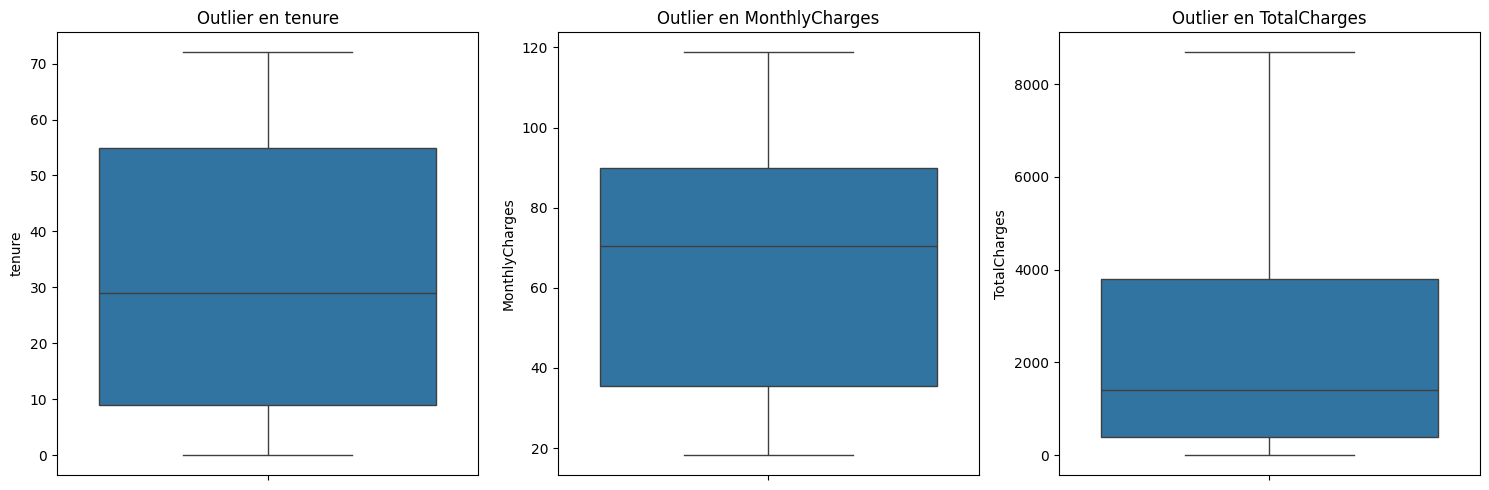

tenure -> Q1: 9.00 | Q3: 55.00 | IQR: 46.00 | Outliers: 0
MonthlyCharges -> Q1: 35.50 | Q3: 89.85 | IQR: 54.35 | Outliers: 0
TotalCharges -> Q1: 398.55 | Q3: 3786.60 | IQR: 3388.05 | Outliers: 0


In [ ]:
######## Gestion de valores Atipicos (Outlier) ########

########## Diagrama de caja #############

#### Identificamos mediante IQR ####

columnas_numericas = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, columna in enumerate(columnas_numericas):
    sb.boxplot(data=df, y=columna, ax=axes[i])
    axes[i].set_title(f"Outlier en {columna}")

plt.tight_layout()
plt.show()


######## Identificador de Outliers mediante IQR ########

for columna in columnas_numericas:
    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)
    IQR = Q3 - Q1
    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR
    outliers = df[(df[columna] < limite_inf) | (df[columna] > limite_sup)]
    print(f"{columna} -> Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f} | Outliers: {len(outliers)}")

# Justificación: No se detectan valores atípicos fuera del rango intercuartílico y los montos/antigüedades
# representan casos reales del negocio, por lo que se conservan todos los registros.


In [4]:
# RESUMENES
# resume = pd.DataFrame({
#     'Tipo_Dato': df.dtypes,
#     'Valores_Unicos': df.nunique(),
#     'Ejemplo_Valor': df.iloc[0]
# })
# display(resume)

# print("<=== Valores únicos en columnas de texto (categóricas) ===>\n")
# # Filtramos solo las columnas que son texto (object) o categoría
# columnas_texto = df.select_dtypes(include=['object', 'category']).columns

# for col in columnas_texto:
#     # Omitimos la columna de ID porque tiene 7000+ valores únicos y saturaría la pantalla
#     if col == 'customerID':
#         continue

#     print(f"🔹 [{col}] - ({df[col].nunique()} valores únicos)")

#     # value_counts() muestra cada valor y cuántas veces se repite
#     print(df[col].value_counts())
#     print("-" * 40)

# print("=== Valores únicos en columnas numéricas ===\n")
# columnas_numericas = df.select_dtypes(include=['int64', 'float64']).columns

# for col in columnas_numericas:
#     print(f"🔹 [{col}] - ({df[col].nunique()} valores únicos)")
#     print(df[col].value_counts().sort_index()) # sort_index ordena por el valor (ej: 0 luego 1)
#     print("-" * 40)

,Tipo_Dato,Valores_Unicos,Ejemplo_Valor
customerID,object,7043,7590-VHVEG
gender,object,2,Female
SeniorCitizen,int64,2,0
Partner,object,2,Yes
Dependents,object,2,No
tenure,int64,73,1
PhoneService,object,2,No
MultipleLines,object,3,No phone service
InternetService,object,3,DSL
OnlineSecurity,object,3,No


<=== Valores únicos en columnas de texto (categóricas) ===>

🔹 [gender] - (2 valores únicos)
gender
Male      3555
Female    3488
Name: count, dtype: int64
----------------------------------------
🔹 [Partner] - (2 valores únicos)
Partner
No     3641
Yes    3402
Name: count, dtype: int64
----------------------------------------
🔹 [Dependents] - (2 valores únicos)
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
----------------------------------------
🔹 [PhoneService] - (2 valores únicos)
PhoneService
Yes    6361
No      682
Name: count, dtype: int64
----------------------------------------
🔹 [MultipleLines] - (3 valores únicos)
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
----------------------------------------
🔹 [InternetService] - (3 valores únicos)
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
----------------------------------------
🔹 [OnlineSec

In [6]:
# GRAFICOS ESTADISTICOS

# Configurar estilo
sb.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

# titulares
titulos_amigables = {
    'gender': 'Género',
    'Partner': 'Tiene Pareja',
    'Dependents': 'Tiene Dependientes',
    'SeniorCitizen': 'Es Ciudadano Mayor'
}

# ==========================================
# Funciones con graficos
# ==========================================

# ==========================================
# Gráfico de condiciones sociodemográficas
# ==========================================
def graficar_condiciones_sociodemograficas(df):
    columnas = ['gender', 'Partner', 'Dependents', 'SeniorCitizen']
    titulos = ['Género', 'Tiene Pareja', 'Tiene Dependientes', 'Es Ciudadano Mayor']

    fig, axes = plt.subplots(2, 2)
    axes = axes.flatten()

    for i, (col, titulo) in enumerate(zip(columnas, titulos)):
        conteos = df[col].value_counts()
        porcentajes = df[col].value_counts(normalize=True) * 100

        colores = ['#a8d5a2', '#f9c784']
        barras = axes[i].bar(conteos.index, conteos.values, color=colores[:len(conteos)])

        for j, barra in enumerate(barras):
            porcentaje = porcentajes.iloc[j]
            cantidad = conteos.iloc[j]

            axes[i].annotate(
                f'{porcentaje:.1f}%\n(n={cantidad})',
                xy=(barra.get_x() + barra.get_width() / 2, barra.get_height()),
                xytext=(0, 5),
                textcoords="offset points",
                ha='center', va='bottom',
                fontsize=10, fontweight='bold'
            )

        max_valor = conteos.max()
        axes[i].set_ylim(0, max_valor * 1.8)
        axes[i].set_title(titulo, fontsize=12, fontweight='bold')
        axes[i].set_ylabel('Cantidad de clientes')
        axes[i].set_xlabel('')

    plt.suptitle('Distribución de cancelación por condiciones sociodemográficas',
                 fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

# ==========================================
# Análisis de servicios por grupo
# ==========================================
def analizar_servicios_por_grupo(columna_grupo, df):
    titulo_grafico = titulos_amigables.get(columna_grupo, columna_grupo)

    servicios_config = {
        'Telefono': {
            'columna': 'PhoneService',
            'condicion': 'Yes',
            'color': '#1f77b4',
            'categoria': 'Teléfono'
        },
        'Multilinea': {
            'columna': 'MultipleLines',
            'condicion': 'Yes',
            'color': '#aec7e8',
            'categoria': 'Teléfono'
        },

        'Internet - Fibra Óptica': {
            'columna': 'InternetService', 'condicion': lambda x: x == 'Fiber optic',
            'color': '#2ca02c', 'categoria': 'Internet'
        },
        'Internet - DSL': {
            'columna': 'InternetService', 'condicion': lambda x: x == 'DSL',
            'color': '#98df8a', 'categoria': 'Internet'
        },
        'Sin Internet': {
            'columna': 'InternetService', 'condicion': lambda x: x == 'No',
            'color': '#c7c7c7', 'categoria': 'Internet'
        },
        'Seguridad Online': {
            'columna': 'OnlineSecurity', 'condicion': 'Yes',
            'color': '#bcbd22', 'categoria': 'Internet'
        },
        'Backup Online': {
            'columna': 'OnlineBackup', 'condicion': 'Yes',
            'color': '#dbdb8d', 'categoria': 'Internet'
        },
        'Proteccion Disp.': {
            'columna': 'DeviceProtection', 'condicion': 'Yes',
            'color': '#7f7f7f', 'categoria': 'Internet'
        },
        'Soporte Tecnico': {
            'columna': 'TechSupport', 'condicion': 'Yes',
            'color': '#5a5a5a', 'categoria': 'Internet'
        },

        'Streaming TV': {
            'columna': 'StreamingTV',
            'condicion': 'Yes',
            'color': '#d62728',
            'categoria': 'Streaming'
        },
        'Streaming Movies': {
            'columna': 'StreamingMovies',
            'condicion': 'Yes',
            'color': '#ff7f0e',
            'categoria': 'Streaming'
        }
    }

    resultados = {}
    for categoria in df[columna_grupo].unique():
        subset = df[df[columna_grupo] == categoria]
        tasas = {}

        for nombre_servicio, config in servicios_config.items():
            columna_servicio = config['columna']
            condicion = config['condicion']

            if callable(condicion):
                cumple_condicion = condicion(subset[columna_servicio])
            else:
                cumple_condicion = subset[columna_servicio] == condicion

            tasa = (cumple_condicion.sum() / len(subset)) * 100
            tasas[nombre_servicio] = tasa

        resultados[categoria] = tasas

    plot_df = pd.DataFrame(resultados).T
    colores_servicios = [servicios_config[col]['color'] for col in plot_df.columns]

    plt.figure(figsize=(12, 7))
    ax = plot_df.plot(kind='barh', color=colores_servicios, edgecolor='white', legend=False)

    plt.title(f'Adopción de Servicios según: {titulo_grafico}', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Porcentaje de clientes dentro del grupo (%)', fontsize=11)
    plt.ylabel('')
    plt.xlim(0, 105)

    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(f'{width:.1f}%',
                        (width, p.get_y() + p.get_height() / 2.),
                        ha='left', va='center',
                        xytext=(5, 0), textcoords='offset points',
                        fontsize=9, color='black')

    # Leyenda actualizada con el desglose de Internet
    leyenda_elementos = []
    leyenda_elementos.append(Patch(facecolor='#1f77b4', label='Teléfono'))
    leyenda_elementos.append(Patch(facecolor='#aec7e8', label=' └─ Multilínea'))

    leyenda_elementos.append(Patch(facecolor='#2ca02c', label='Internet: Fibra Óptica'))
    leyenda_elementos.append(Patch(facecolor='#98df8a', label=' └─ Internet: DSL'))
    leyenda_elementos.append(Patch(facecolor='#c7c7c7', label=' └─ Sin Internet'))
    leyenda_elementos.append(Patch(facecolor='#bcbd22', label=' └─ Seguridad Online'))
    leyenda_elementos.append(Patch(facecolor='#dbdb8d', label=' └─ Backup Online'))
    leyenda_elementos.append(Patch(facecolor='#7f7f7f', label=' └─ Protección Disp.'))
    leyenda_elementos.append(Patch(facecolor='#5a5a5a', label=' └─ Soporte Técnico'))

    leyenda_elementos.append(Patch(facecolor='#d62728', label='Streaming TV'))
    leyenda_elementos.append(Patch(facecolor='#ff7f0e', label=' └─ Streaming Movies'))

    plt.legend(handles=leyenda_elementos, title='Servicios',
               bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9,
               frameon=True, fancybox=True, shadow=True)

    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

# ==========================================
# Análisis de contratación y facturación por grupo
# ==========================================
def analizar_contratacion_por_grupo(columna_grupo, df):
    titulo_grafico = titulos_amigables.get(columna_grupo, columna_grupo)

    # Configurar las 3 variables de contratación/facturación
    contratacion_config = {
        'Contrato: Mes a Mes': {
            'columna': 'Contract',
            'condicion': 'Month-to-month',
            'color': '#9467bd',
            'categoria': 'Tipo de Contrato'
        },
        'Contrato: 1 Año': {
            'columna': 'Contract',
            'condicion': 'One year',
            'color': '#8c564b',
            'categoria': 'Tipo de Contrato'
        },
        'Contrato: 2 Años': {
            'columna': 'Contract',
            'condicion': 'Two year',
            'color': '#e377c2',
            'categoria': 'Tipo de Contrato'
        },

        # 📄 FACTURACIÓN SIN PAPEL (Verdes)
        'Facturación: Sin Papel': {
            'columna': 'PaperlessBilling',
            'condicion': 'Yes',
            'color': '#17becf',
            'categoria': 'Facturación'
        },
        'Facturación: Con Papel': {
            'columna': 'PaperlessBilling',
            'condicion': 'No',
            'color': '#1f77b4',
            'categoria': 'Facturación'
        },

        # 💳 MÉTODOS DE PAGO (Naranjas/Rojos)
        'Pago: Cheque Electrónico': {
            'columna': 'PaymentMethod',
            'condicion': 'Electronic check',
            'color': '#ff7f0e',
            'categoria': 'Método de Pago'
        },
        'Pago: Cheque por Correo': {
            'columna': 'PaymentMethod',
            'condicion': 'Mailed check',
            'color': '#d62728',
            'categoria': 'Método de Pago'
        },
        'Pago: Transferencia Bancaria': {
            'columna': 'PaymentMethod',
            'condicion': 'Bank transfer (automatic)',
            'color': '#2ca02c',
            'categoria': 'Método de Pago'
        },
        'Pago: Tarjeta de Crédito': {
            'columna': 'PaymentMethod',
            'condicion': 'Credit card (automatic)',
            'color': '#9467bd',
            'categoria': 'Método de Pago'
        }
    }

    # Calcular porcentajes por grupo
    resultados = {}
    for categoria in df[columna_grupo].unique():
        subset = df[df[columna_grupo] == categoria]
        tasas = {}

        for nombre_variable, config in contratacion_config.items():
            columna_servicio = config['columna']
            condicion = config['condicion']

            if callable(condicion):
                cumple_condicion = condicion(subset[columna_servicio])
            else:
                cumple_condicion = subset[columna_servicio] == condicion

            tasa = (cumple_condicion.sum() / len(subset)) * 100
            tasas[nombre_variable] = tasa

        resultados[categoria] = tasas

    plot_df = pd.DataFrame(resultados).T
    colores_contratacion = [contratacion_config[col]['color'] for col in plot_df.columns]

    # Graficar
    plt.figure(figsize=(12, 7))
    ax = plot_df.plot(kind='barh', color=colores_contratacion, edgecolor='white', legend=False)

    plt.title(f'Contratación y Facturación según: {titulo_grafico}', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Porcentaje de clientes dentro del grupo (%)', fontsize=11)
    plt.ylabel('')
    plt.xlim(0, 105)

    # Etiquetas de porcentaje
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(f'{width:.1f}%',
                        (width, p.get_y() + p.get_height() / 2.),
                        ha='left', va='center',
                        xytext=(5, 0), textcoords='offset points',
                        fontsize=9, color='black')

    # Leyenda agrupada por categoría
    leyenda_elementos = []
    leyenda_elementos.append(Patch(facecolor='#9467bd', label='Contrato: Mes a Mes'))
    leyenda_elementos.append(Patch(facecolor='#8c564b', label=' └─ Contrato: 1 Año'))
    leyenda_elementos.append(Patch(facecolor='#e377c2', label=' └─ Contrato: 2 Años'))

    leyenda_elementos.append(Patch(facecolor='#17becf', label='Facturación: Sin Papel'))
    leyenda_elementos.append(Patch(facecolor='#1f77b4', label=' └─ Facturación: Con Papel'))

    leyenda_elementos.append(Patch(facecolor='#ff7f0e', label='Pago: Cheque Electrónico'))
    leyenda_elementos.append(Patch(facecolor='#d62728', label=' └─ Pago: Cheque por Correo'))
    leyenda_elementos.append(Patch(facecolor='#2ca02c', label=' └─ Pago: Transferencia'))
    leyenda_elementos.append(Patch(facecolor='#9467bd', label=' └─ Pago: Tarjeta Crédito'))

    plt.legend(handles=leyenda_elementos, title='Contratación y Facturación',
               bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9,
               frameon=True, fancybox=True, shadow=True)

    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

# ==========================================
# Análisis de Gastos (Mensuales y Totales) por Grupo
# ==========================================
def analizar_gastos_por_grupo(columna_grupo, df):
    titulo_grafico = titulos_amigables.get(columna_grupo, columna_grupo)

    # 1. Limpieza segura de TotalCharges
    df_clean = df.copy()
    df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
    df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)

    # 2. Calcular promedios por categoría del grupo
    resumen_gastos = df_clean.groupby(columna_grupo).agg(
        Monthly_Promedio=('MonthlyCharges', 'mean'),
        Total_Promedio=('TotalCharges', 'mean')
    ).reset_index()

    # 3. Configurar el gráfico
    fig, ax1 = plt.subplots(figsize=(10, 6))

    categorias = resumen_gastos[columna_grupo]
    x_pos = np.arange(len(categorias))

    # --- EJE IZQUIERDO: Cargo Mensual (Barras azules) ---
    color_mensual = '#4C72B0'
    barras = ax1.bar(x_pos, resumen_gastos['Monthly_Promedio'], color=color_mensual, alpha=0.8, width=0.4, label='Cargo Mensual Promedio')
    ax1.set_ylabel('Cargo Mensual Promedio ($)', color=color_mensual, fontweight='bold', fontsize=11)
    ax1.tick_params(axis='y', labelcolor=color_mensual)

    max_mensual = resumen_gastos['Monthly_Promedio'].max()
    ax1.set_ylim(0, max_mensual * 2.0)

    # Etiquetas azules (sin cambios)
    for barra in barras:
        altura = barra.get_height()
        ax1.annotate(f'${altura:.0f}',
                     xy=(barra.get_x() + barra.get_width() / 2, altura),
                     xytext=(0, 8), textcoords="offset points",
                     ha='center', va='bottom', fontsize=10, fontweight='bold', color=color_mensual)

    # --- EJE DERECHO: Cargo Total (Línea naranja) ---
    ax2 = ax1.twinx()
    color_total = '#DD8452'
    linea = ax2.plot(x_pos, resumen_gastos['Total_Promedio'], color=color_total, marker='o',
                     markersize=10, linewidth=3, label='Cargo Total Promedio')
    ax2.set_ylabel('Cargo Total Promedio ($)', color=color_total, fontweight='bold', fontsize=11)
    ax2.tick_params(axis='y', labelcolor=color_total)

    max_total = resumen_gastos['Total_Promedio'].max()
    ax2.set_ylim(0, max_total * 2.5)

    for i, valor in enumerate(resumen_gastos['Total_Promedio']):
        ax2.annotate(f'${valor:.0f}',
                     xy=(x_pos[i], valor),
                     xytext=(0, 15), textcoords="offset points",
                     ha='center', va='bottom', fontsize=10, fontweight='bold', color=color_total,
                     bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='none', alpha=0.85))

    # 4. Formato general
    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(categorias, fontsize=11, fontweight='bold')
    ax1.set_xlabel('')

    plt.title(f'Gastos Promedio según: {titulo_grafico}', fontsize=14, fontweight='bold', pad=15)

    # Leyenda combinada
    lineas_leyenda = list(barras) + list(linea)
    etiquetas_leyenda = [l.get_label() for l in lineas_leyenda]
    ax1.legend(lineas_leyenda, etiquetas_leyenda, loc='upper left', fontsize=10, frameon=True, fancybox=True, shadow=True)

    plt.tight_layout()
    plt.show()

In [7]:
# ==========================================
# Tasa de Churn por cualquier variable categórica
# ==========================================
def analizar_tasa_churn_por_variable(columna, df, titulo_amigable):
    # 1. Calcular tasa de churn y cantidad de clientes por categoría
    resumen = df.groupby(columna).agg(
        Tasa_Churn=('Churn_Num', lambda x: (x == 1).mean() * 100),
        Total_Clientes=('Churn_Num', 'count')
    ).reset_index()

    # 2. ORDENAR por Tasa de Churn descendente (¡Clave para el análisis!)
    resumen = resumen.sort_values(by='Tasa_Churn', ascending=False).reset_index(drop=True)

    # 3. Configurar gráfico horizontal (mejor para nombres largos)
    plt.figure(figsize=(10, 6))

    # Color dinámico: más rojo si el churn es alto, más verde si es bajo
    colores = ['#d62728' if x > 30 else '#ff7f0e' if x > 20 else '#2ca02c' for x in resumen['Tasa_Churn']]

    barras = plt.barh(resumen[columna], resumen['Tasa_Churn'], color=colores, edgecolor='white')

    # 4. Etiquetas con porcentaje y cantidad
    for i, barra in enumerate(barras):
        tasa = resumen['Tasa_Churn'].iloc[i]
        n = resumen['Total_Clientes'].iloc[i]
        plt.annotate(f'{tasa:.1f}%  (n={n})',
                     xy=(tasa, i),
                     xytext=(5, 0), textcoords='offset points',
                     ha='left', va='center', fontsize=10, fontweight='bold', color='black')

    # 5. Formato
    plt.title(f'Tasa de Abandono (Churn) según: {titulo_amigable}', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Porcentaje de clientes que cancelaron (%)', fontsize=11)
    plt.ylabel('')
    plt.xlim(0, max(resumen['Tasa_Churn']) * 1.2) # Margen para las etiquetas

    # Línea de referencia del promedio general de churn
    churn_promedio_total = df['Churn_Num'].mean() * 100
    plt.axvline(x=churn_promedio_total, color='black', linestyle='--', linewidth=2,
                label=f'Promedio General ({churn_promedio_total:.1f}%)')
    plt.legend(loc='lower right', fontsize=10)

    plt.gca().invert_yaxis() # Para que el mayor riesgo quede arriba
    plt.tight_layout()
    plt.show()

# ==========================================
# Gastos (Mensuales y Totales) vs Churn
# ==========================================
def analizar_gastos_vs_churn(df):
    df_clean = df.copy()
    df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce').fillna(0)

    df_clean['Churn_Etiqueta'] = df_clean['Churn_Num'].map({0: 'No Abandona (0)', 1: 'Abandona (1)'})

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # --- Gráfico 1: Cargo Mensual vs Churn ---
    sb.boxplot(x='Churn_Etiqueta', y='MonthlyCharges', hue='Churn_Etiqueta',
               data=df_clean, ax=axes[0],
               palette=['#2ca02c', '#d62728'], width=0.5, legend=False)
    axes[0].set_title('Distribución del Cargo Mensual según Churn', fontsize=13, fontweight='bold')
    axes[0].set_ylabel('Cargo Mensual ($)', fontsize=11)
    axes[0].set_xlabel('')

    # --- Gráfico 2: Cargo Total vs Churn ---
    sb.boxplot(x='Churn_Etiqueta', y='TotalCharges', hue='Churn_Etiqueta',
               data=df_clean, ax=axes[1],
               palette=['#2ca02c', '#d62728'], width=0.5, legend=False)
    axes[1].set_title('Distribución del Cargo Total según Churn', fontsize=13, fontweight='bold')
    axes[1].set_ylabel('Cargo Total Acumulado ($)', fontsize=11)
    axes[1].set_xlabel('')

    plt.suptitle('Análisis Financiero: ¿Cuánto pagan los clientes que se van?',
                 fontsize=16, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()


========================= Condiciones Sociales Generales =========================



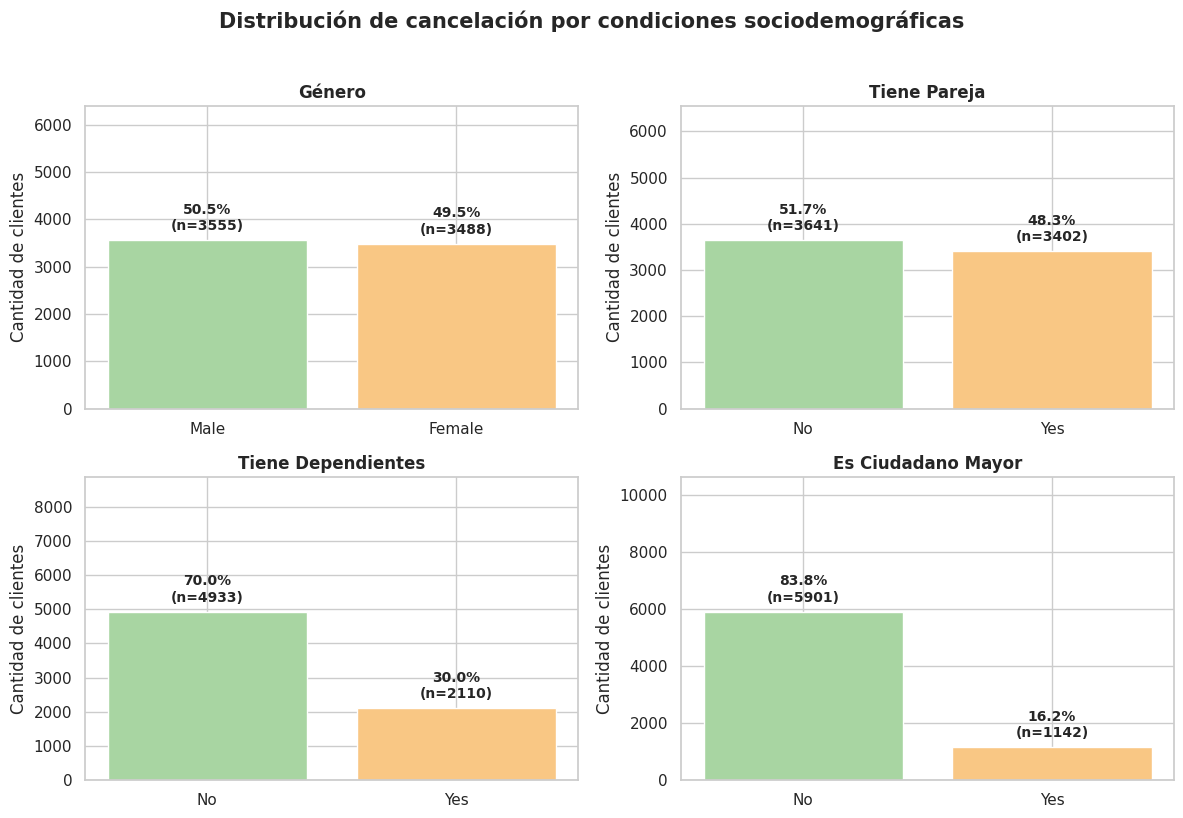

GENDER

========================= SERVICIOS gender=========================



<Figure size 1200x700 with 0 Axes>

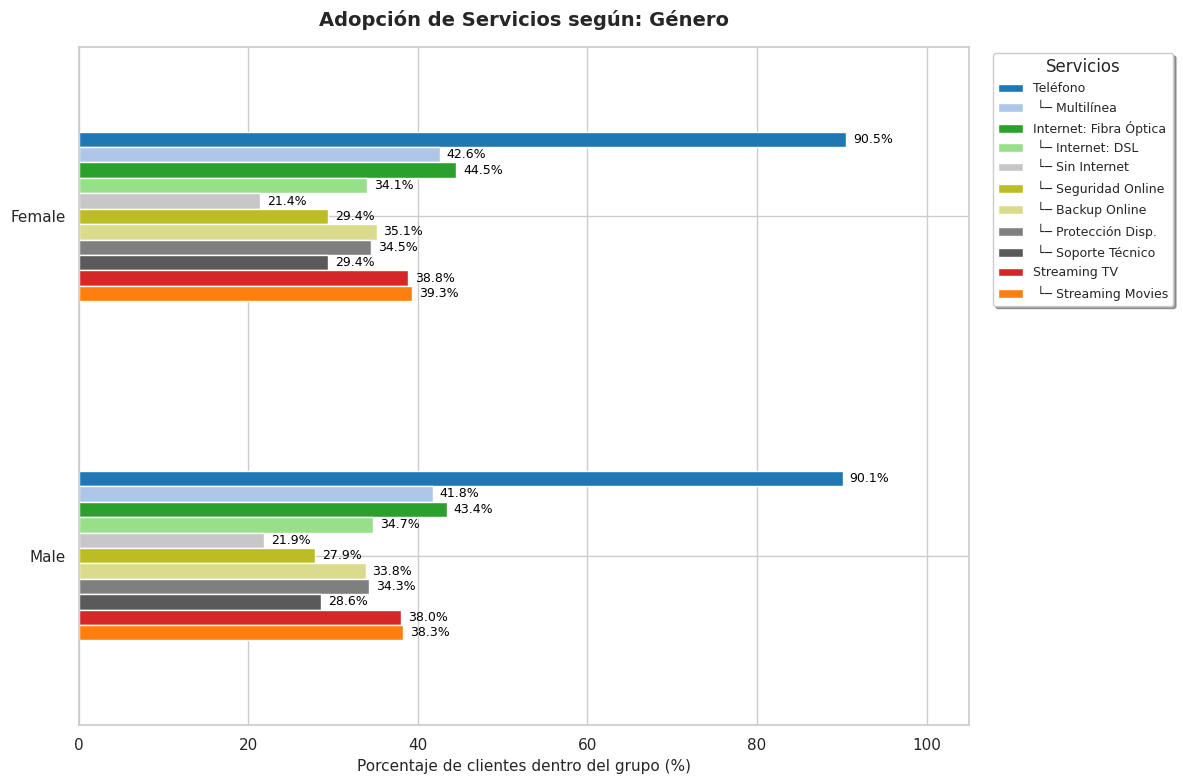


========================= CONTRATACIONES gender=========================



<Figure size 1200x700 with 0 Axes>

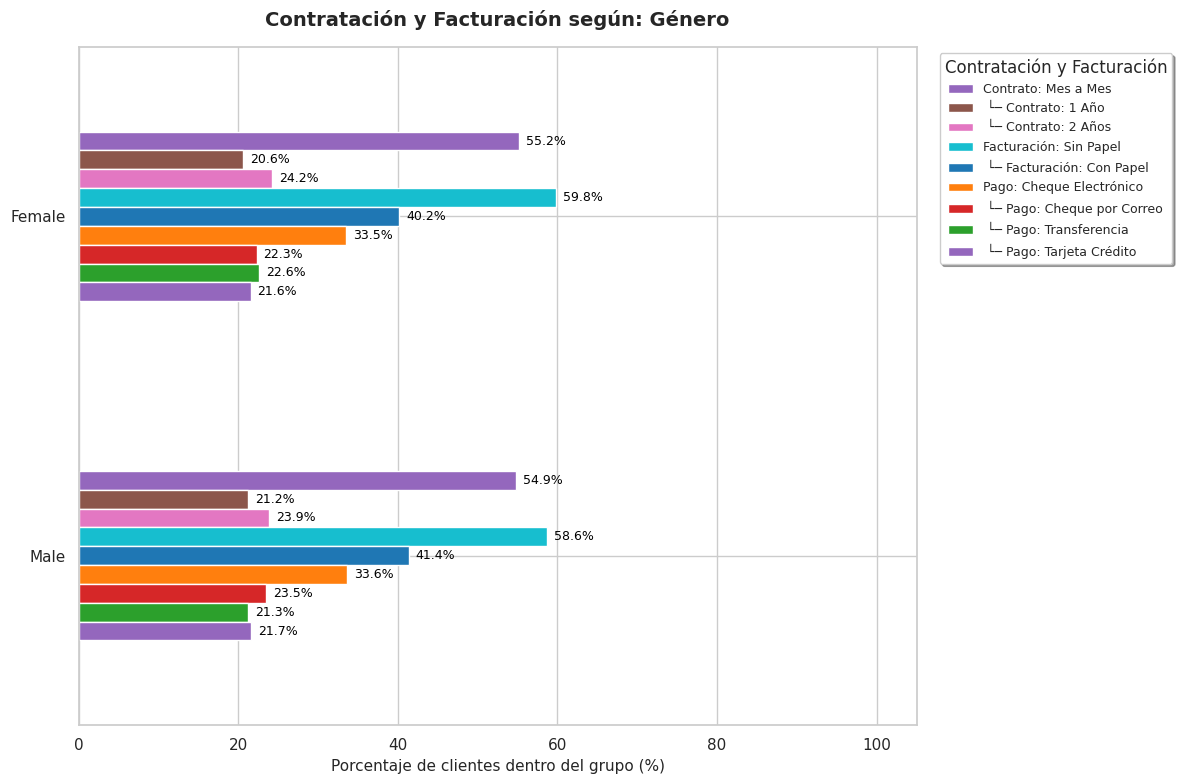


========================= GASTOS gender=========================



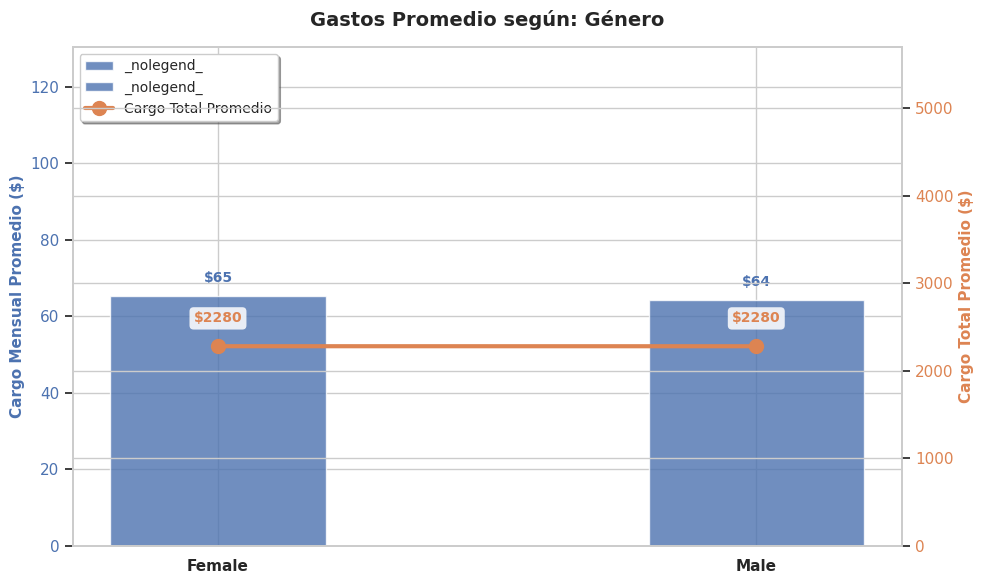



PARTNER

========================= SERVICIOS Partner=========================



<Figure size 1200x700 with 0 Axes>

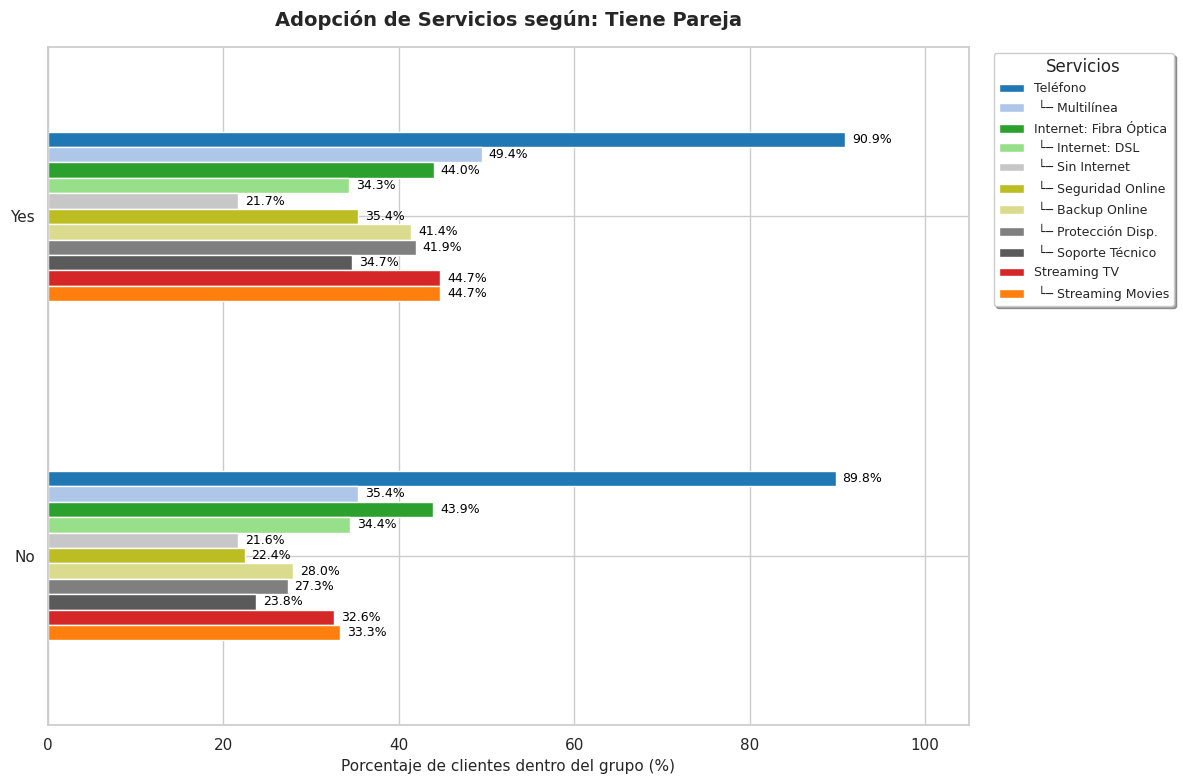


========================= CONTRATACIONES Partner=========================



<Figure size 1200x700 with 0 Axes>

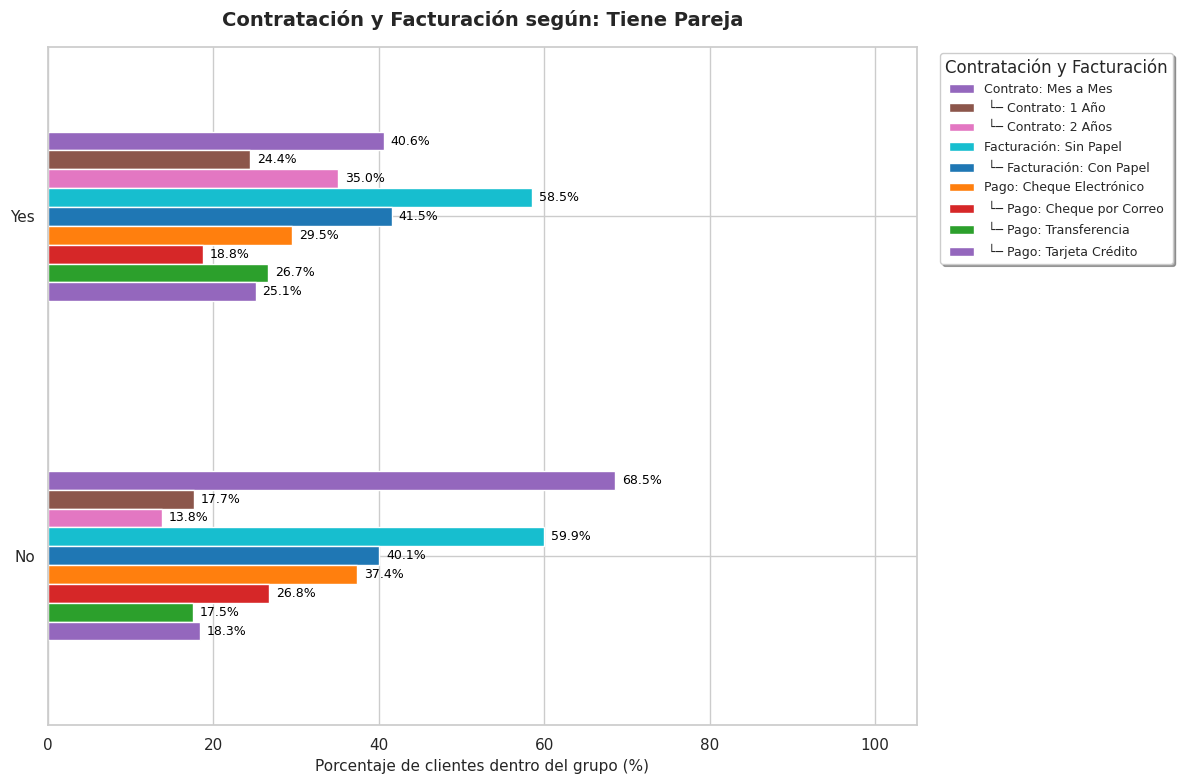


========================= GASTOS Partner=========================



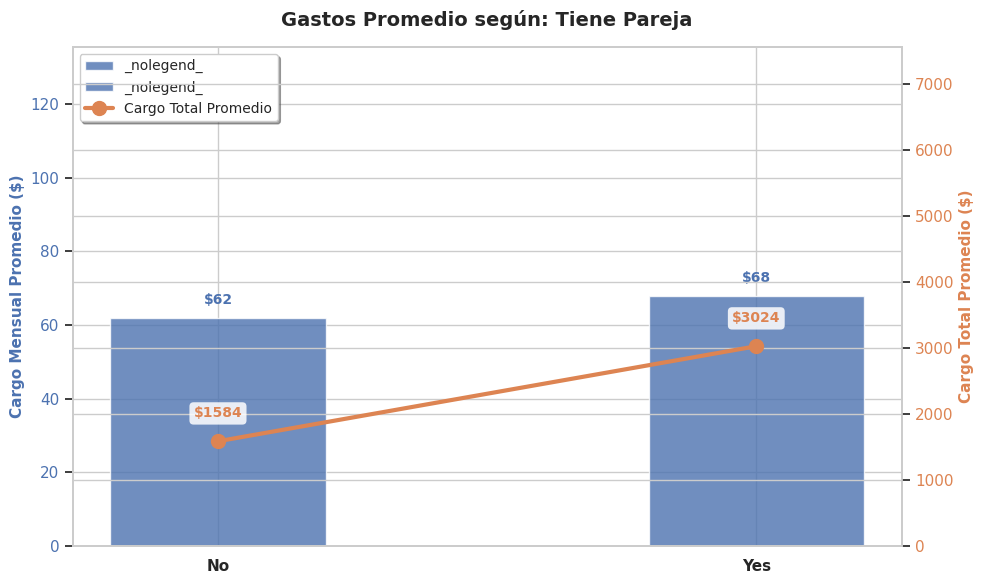



DEPENDENTS

========================= SERVICIOS Dependents=========================



<Figure size 1200x700 with 0 Axes>

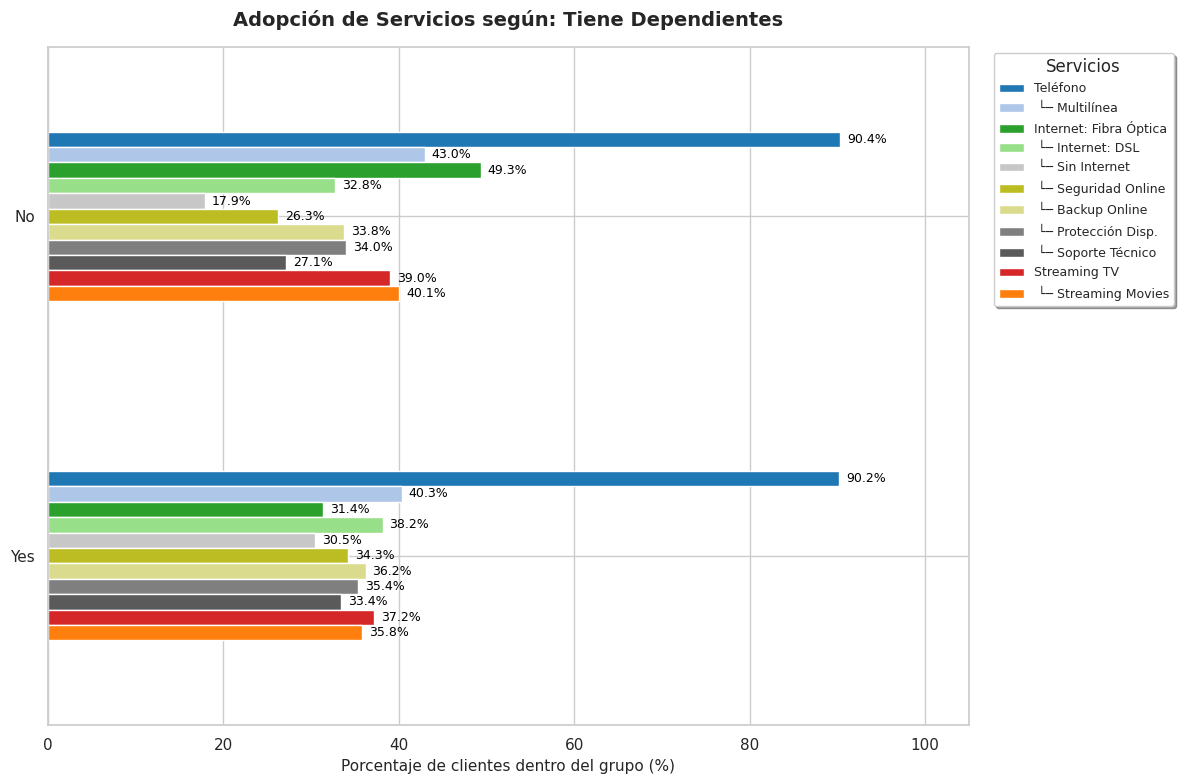


========================= CONTRATACIONES Dependents=========================



<Figure size 1200x700 with 0 Axes>

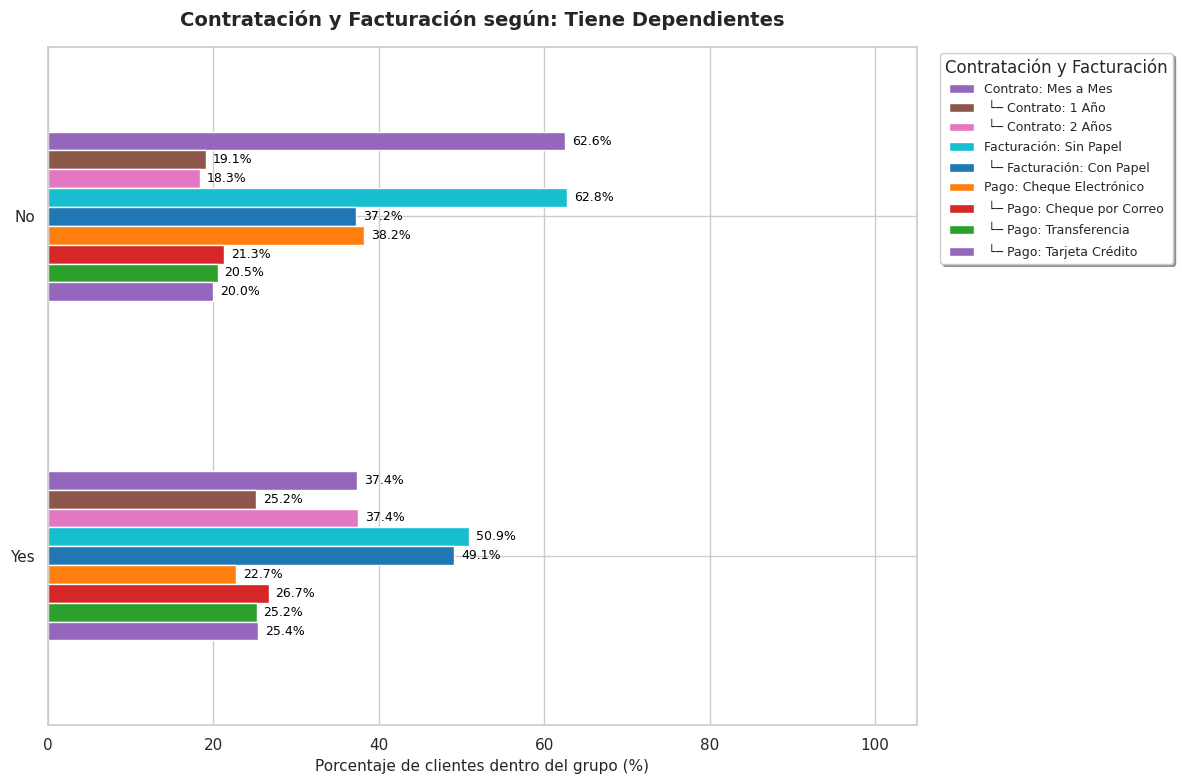


========================= GASTOS Dependents=========================



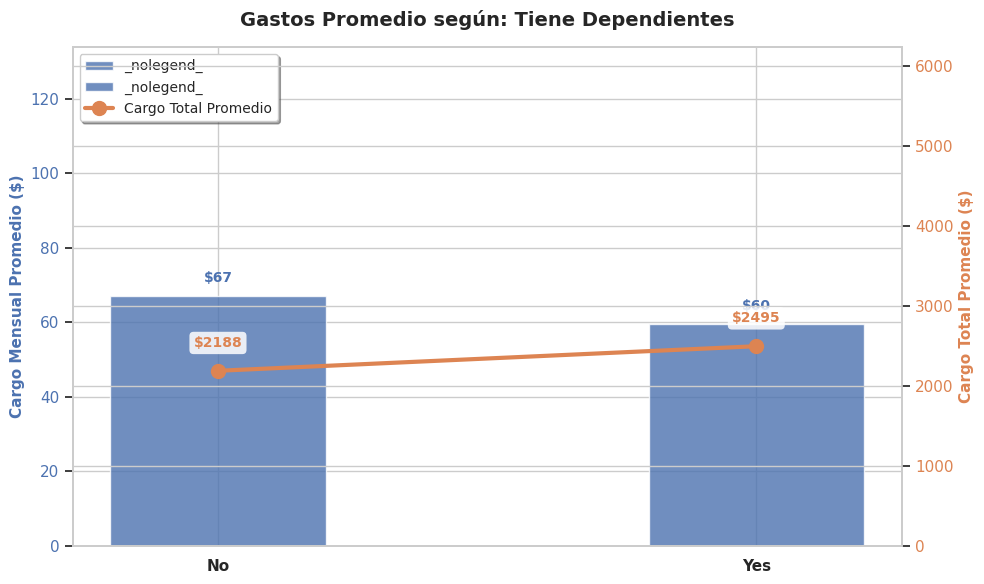



SENIORCITIZEN

========================= SERVICIOS SeniorCitizen=========================



<Figure size 1200x700 with 0 Axes>

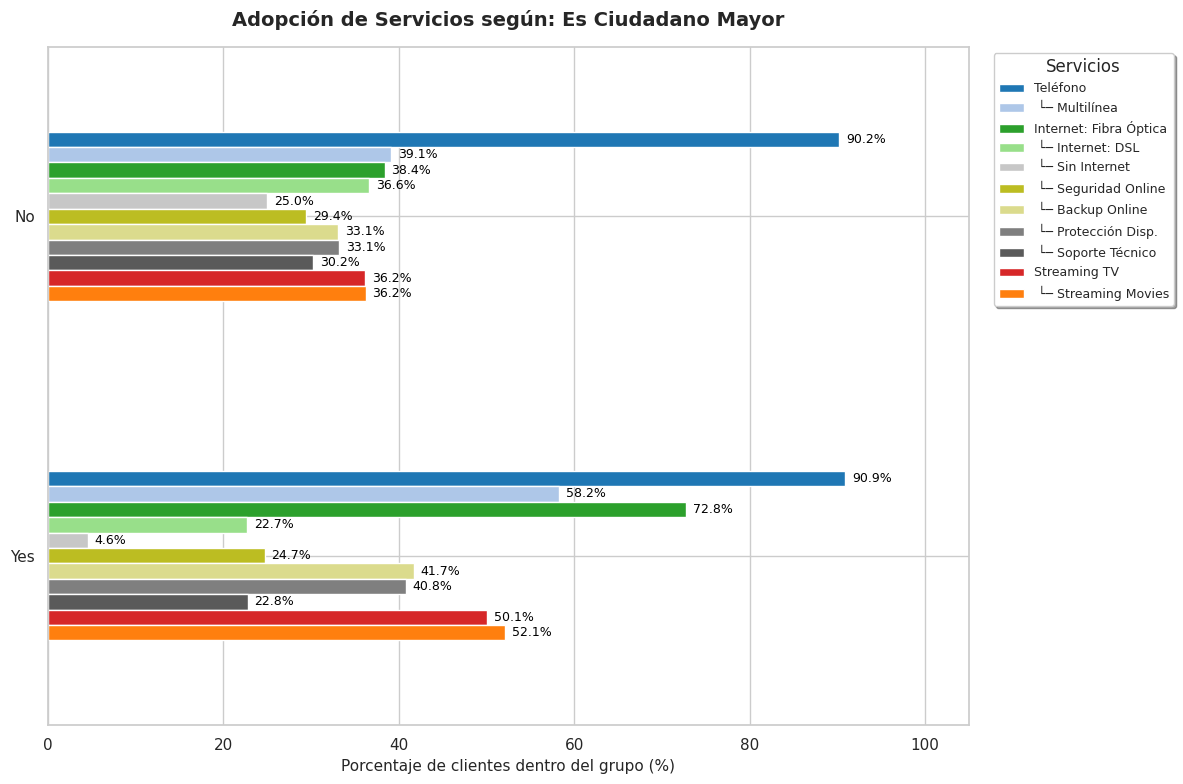


========================= CONTRATACIONES SeniorCitizen=========================



<Figure size 1200x700 with 0 Axes>

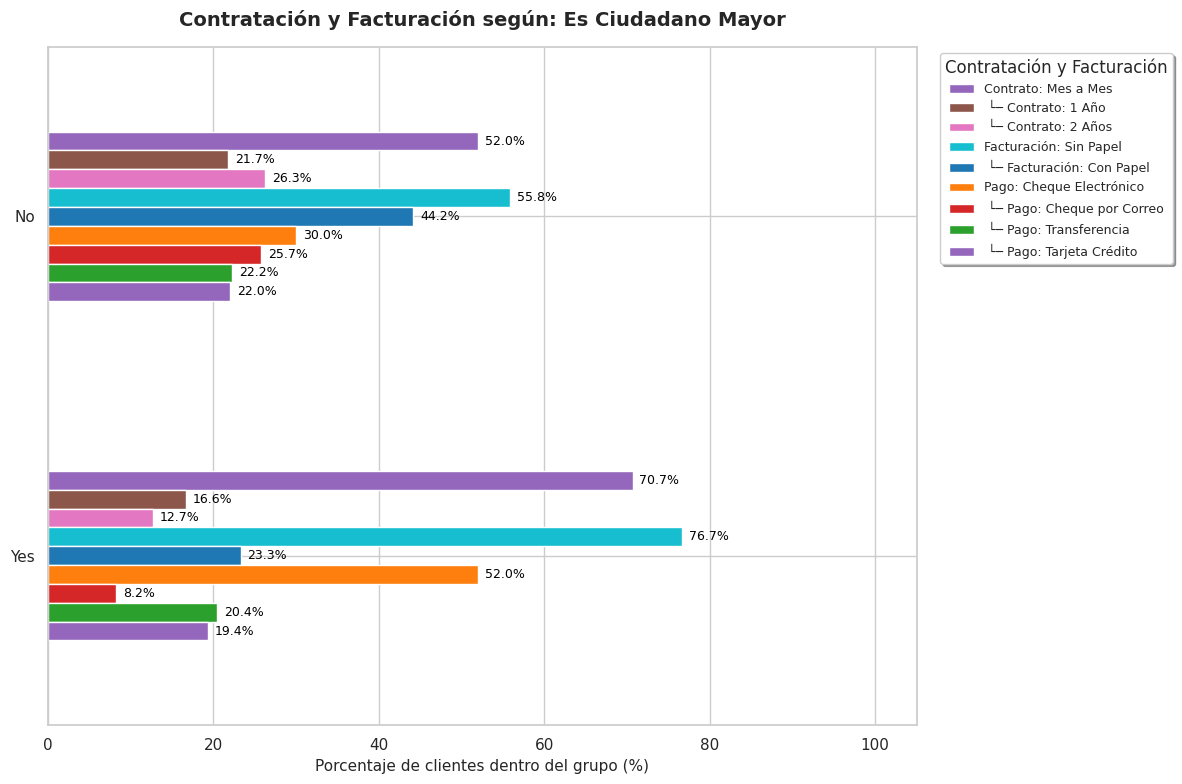


========================= GASTOS SeniorCitizen=========================



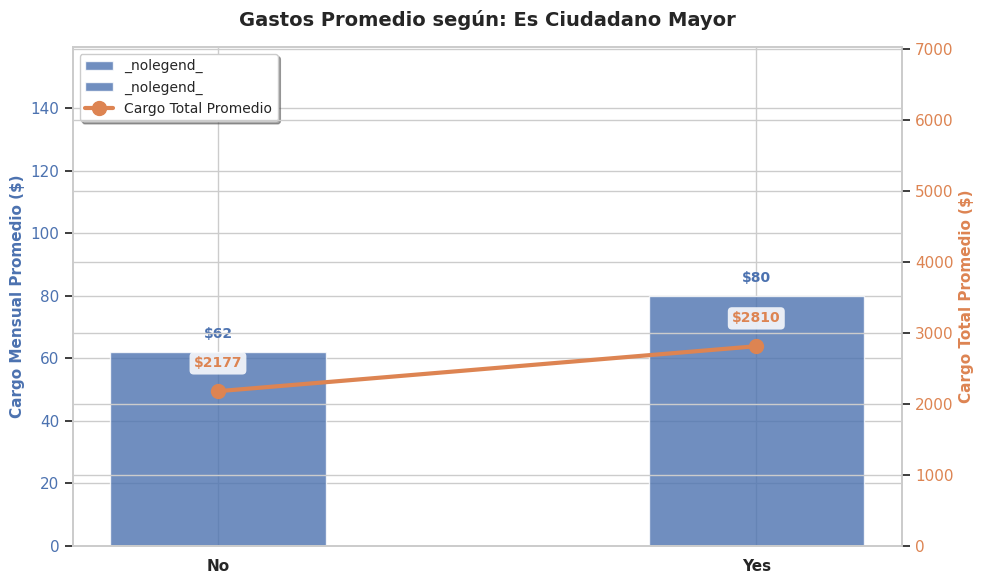

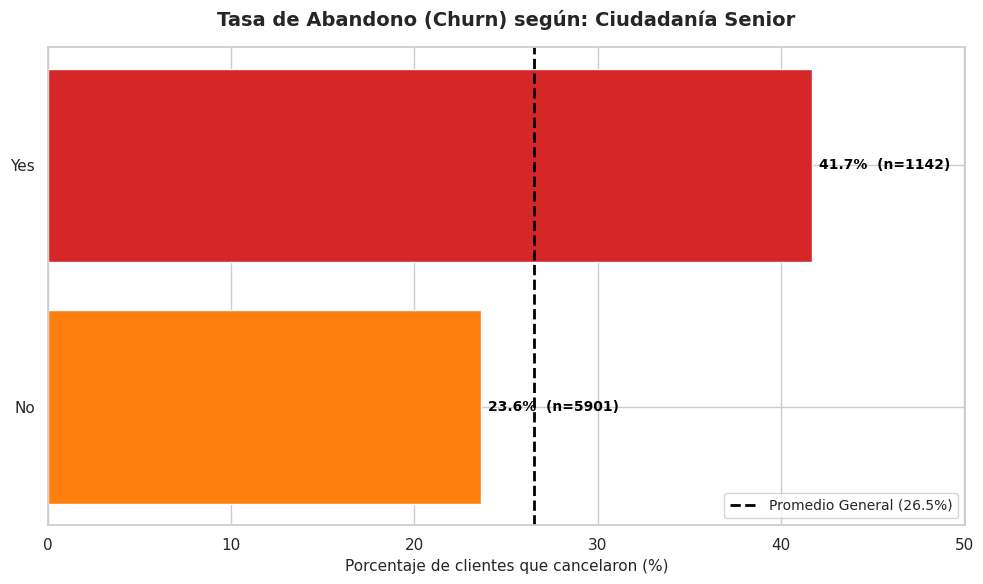

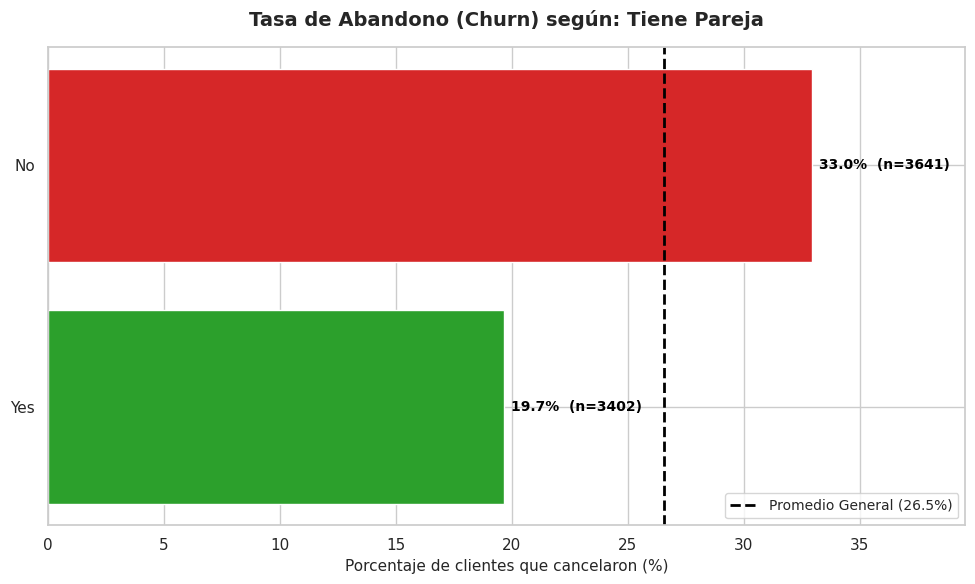

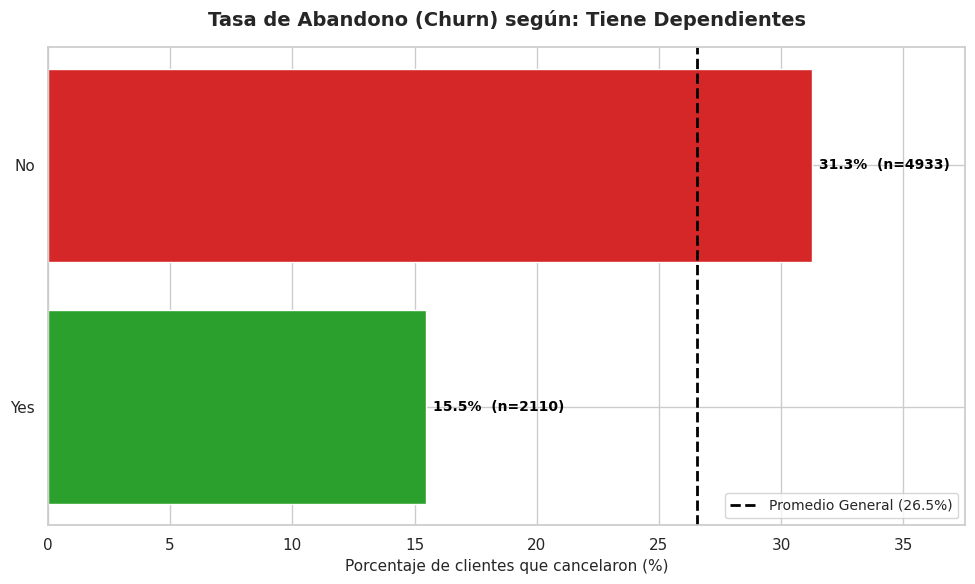

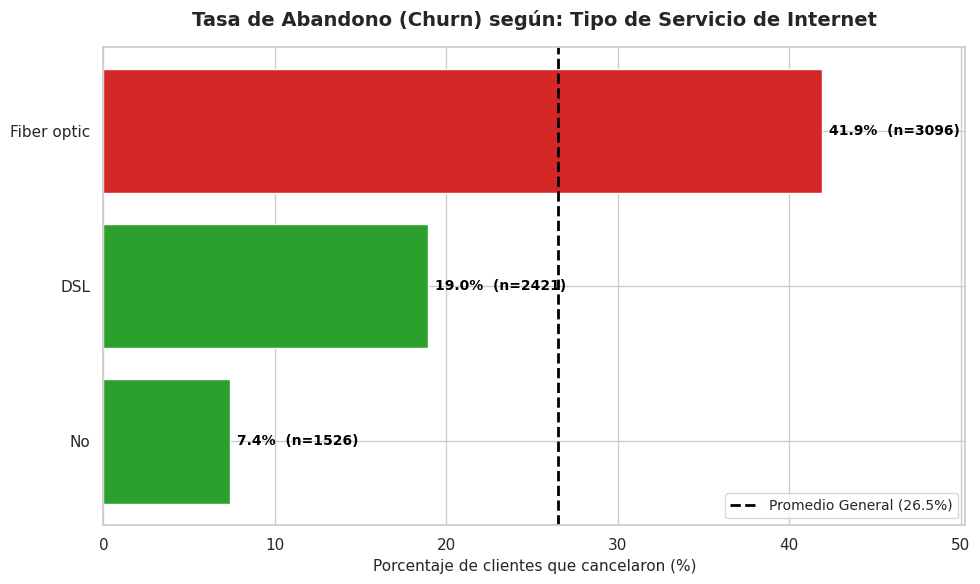

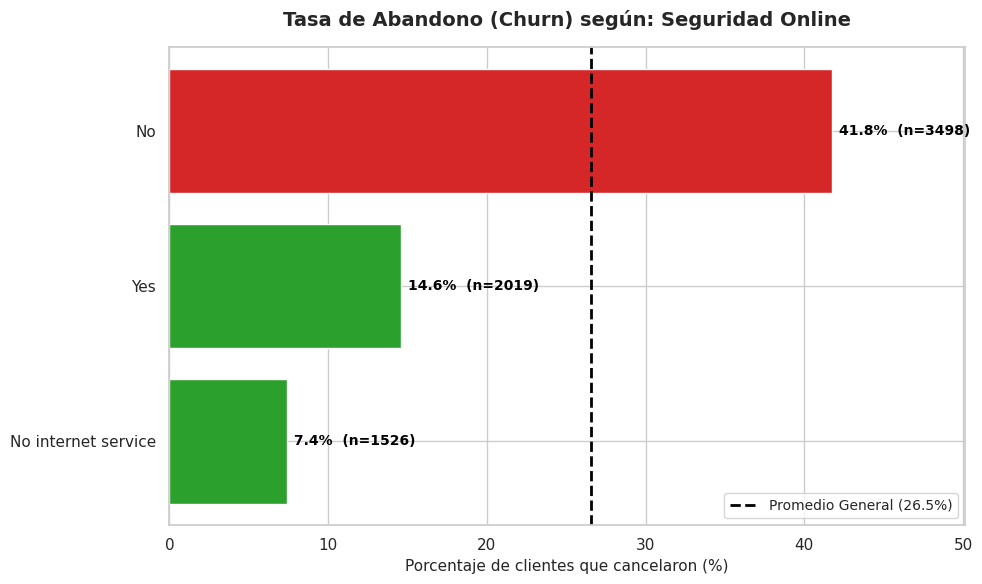

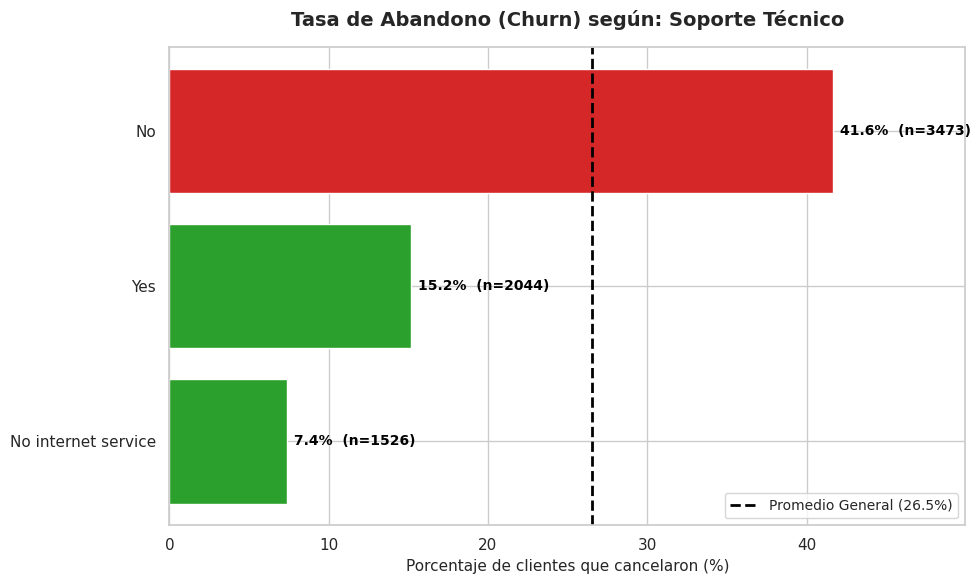

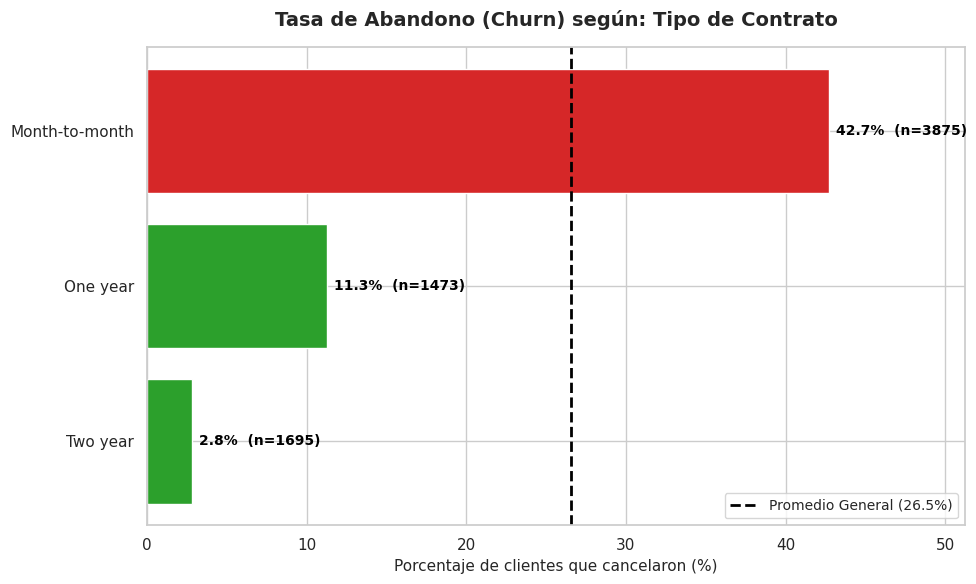

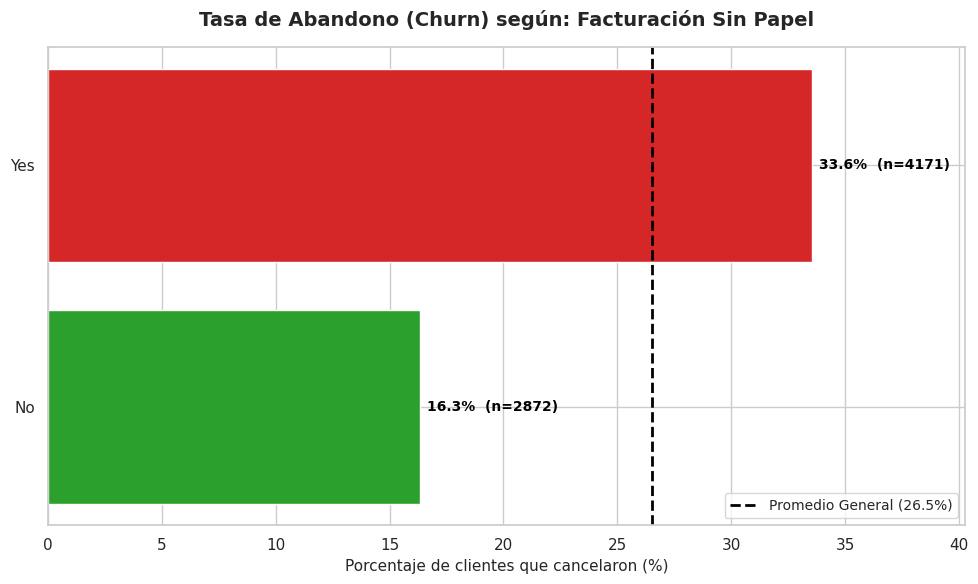

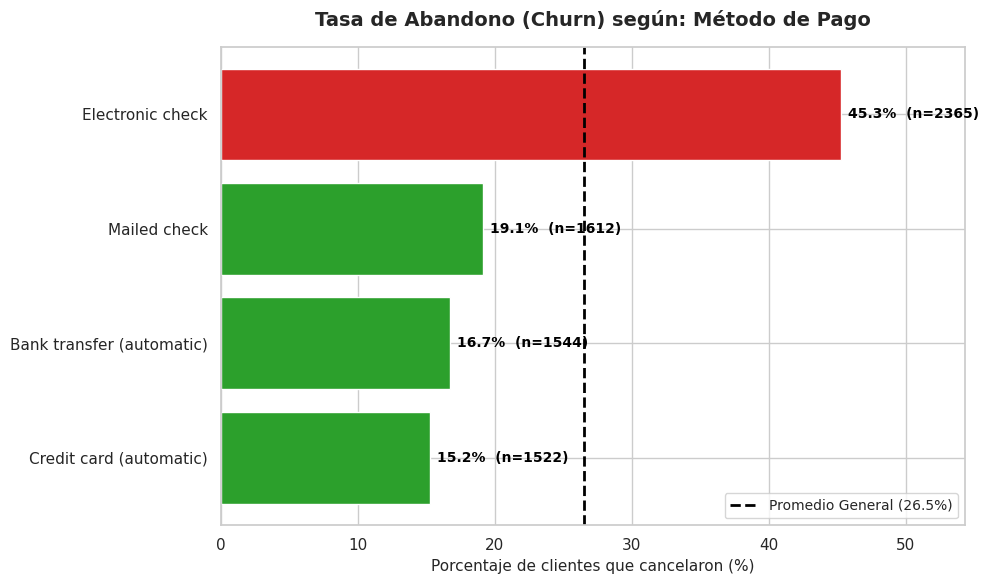


=== ANÁLISIS FINANCIERO VS CHURN ===



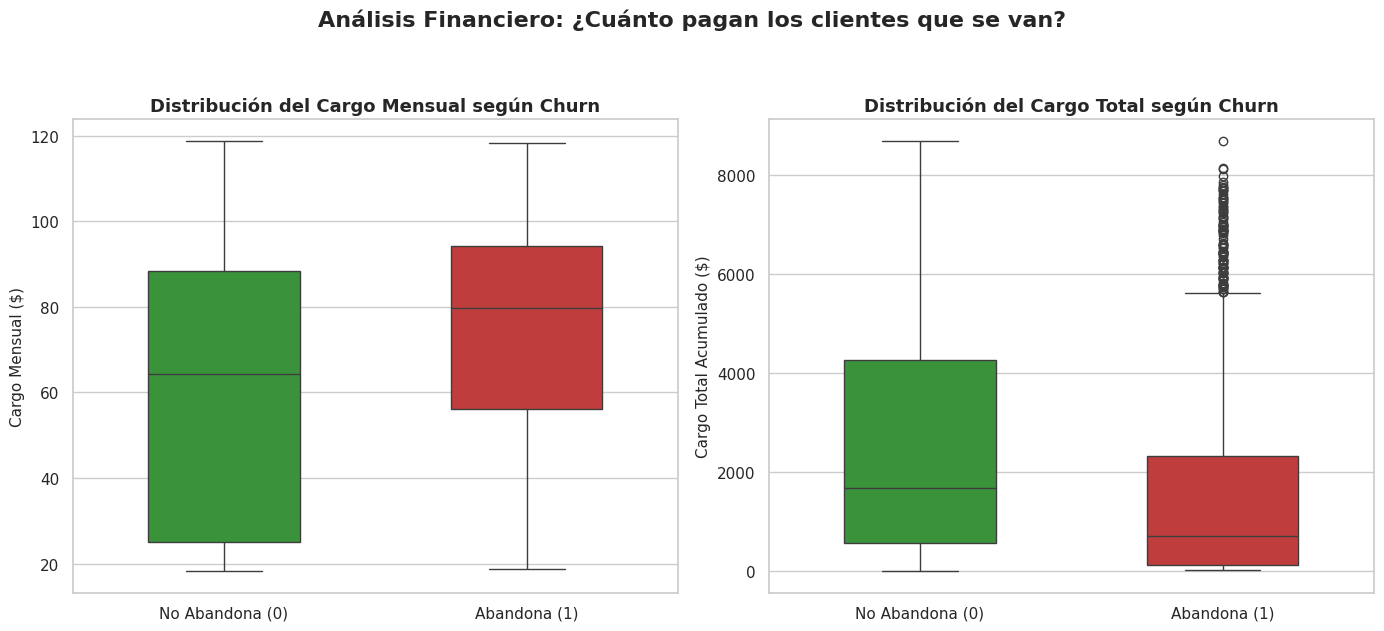

In [14]:
# ==========================================
# EJECUCION
# ==========================================

# 1. Gráfico de condiciones sociodemográficas
print("\n" + "="*25 + ' Condiciones Sociales Generales ' + "="*25 + "\n")
graficar_condiciones_sociodemograficas(df)

# 2. Análisis de servicios por cada grupo
grupos_a_analizar = ['gender', 'Partner', 'Dependents', 'SeniorCitizen']

for grupo in grupos_a_analizar:
    print(grupo.upper())
    print("\n" + "="*25 + ' SERVICIOS ' + grupo + "="*25 + "\n")
    analizar_servicios_por_grupo(grupo, df)
    print("\n" + "="*25 + ' CONTRATACIONES ' + grupo + "="*25 + "\n")
    analizar_contratacion_por_grupo(grupo, df)
    print("\n" + "="*25 + ' GASTOS ' + grupo + "="*25 + "\n")
    analizar_gastos_por_grupo(grupo, df)
    print("\n" + "="*50 + "\n")

# 1. Sociodemográficas
analizar_tasa_churn_por_variable('SeniorCitizen', df, 'Ciudadanía Senior')
analizar_tasa_churn_por_variable('Partner', df, 'Tiene Pareja')
analizar_tasa_churn_por_variable('Dependents', df, 'Tiene Dependientes')

# 2. Servicios (Los más impactantes)
analizar_tasa_churn_por_variable('InternetService', df, 'Tipo de Servicio de Internet')
analizar_tasa_churn_por_variable('OnlineSecurity', df, 'Seguridad Online')
analizar_tasa_churn_por_variable('TechSupport', df, 'Soporte Técnico')

# 3. Contrato y Facturación (¡Los más importantes para el negocio!)
analizar_tasa_churn_por_variable('Contract', df, 'Tipo de Contrato')
analizar_tasa_churn_por_variable('PaperlessBilling', df, 'Facturación Sin Papel')
analizar_tasa_churn_por_variable('PaymentMethod', df, 'Método de Pago')

print("\n=== ANÁLISIS FINANCIERO VS CHURN ===\n")
analizar_gastos_vs_churn(df)